# Lesson 11: A derived five-level satisfaction score

The data contains a binary satisfaction label, not independent five-star ratings. This experiment creates five levels using the label and service scores. Evaluation measures agreement with that constructed target.

**Data:** [Airline Quality Ratings](https://www.kaggle.com/datasets/mikhail1681/airline-quality-ratings). Place `Airline Quality Ratings.csv` in this lesson folder.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

df = pd.read_csv("Airline Quality Ratings.csv")
train, test = train_test_split(df, test_size=0.2, random_state=42,
                               stratify=df["Satisfaction"])
service_cols = ["Departure and Arrival Time Convenience", "Ease of Online Booking",
    "Check-in Service", "Online Boarding", "Gate Location", "On-board Service",
    "Seat Comfort", "Leg Room Service", "Cleanliness", "Food and Drink",
    "In-flight Service", "In-flight Wifi Service", "In-flight Entertainment",
    "Baggage Handling"]

## Construct the target

Fit the service-score preprocessing, binary model, and thresholds on training rows. Apply those fixed parameters to the test rows. The original label is used to assign the derived test levels, so the resulting scores depend on that label.

In [2]:
score_preprocess = Pipeline([("impute", SimpleImputer(strategy="median")),
                             ("scale", StandardScaler())])
z_train = score_preprocess.fit_transform(train[service_cols])
z_test = score_preprocess.transform(test[service_cols])
binary_train = (train["Satisfaction"] == "Satisfied").astype(int)
weights_model = LogisticRegression(max_iter=2000, class_weight="balanced")
weights_model.fit(z_train, binary_train)
weights = np.abs(weights_model.coef_[0])
weights /= weights.sum()
train_score = z_train @ weights
test_score = z_test @ weights
low_cutoffs = np.quantile(train_score[binary_train == 0], [1/3, 2/3])
high_cutoff = np.quantile(train_score[binary_train == 1], 0.6)

def derived_labels(frame, scores):
    satisfied = frame["Satisfaction"].eq("Satisfied").to_numpy()
    low = np.searchsorted(low_cutoffs, scores, side="left") + 1
    high = np.where(scores < high_cutoff, 4, 5)
    return np.where(satisfied, high, low)

y_train = derived_labels(train, train_score)
y_test = derived_labels(test, test_score)
pd.Series(y_train).value_counts().sort_index().rename("Training rows")

1    19588
2    19587
3    19587
4    27085
5    18057
Name: Training rows, dtype: int64

## Predict the derived levels

Train the classifier without the original satisfaction label or the constructed score. Service ratings remain input features, so the model learns to reproduce part of the target-generation rule.

In [3]:
X_train = train.drop(columns=["ID", "Satisfaction"])
X_test = test.drop(columns=["ID", "Satisfaction"])
categorical = X_train.select_dtypes(include="object").columns.tolist()
numeric = X_train.columns.difference(categorical).tolist()
preprocess = ColumnTransformer([
    ("categorical", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                              ("encode", OneHotEncoder(handle_unknown="ignore"))]), categorical),
    ("numeric", SimpleImputer(strategy="median"), numeric),
])
model = Pipeline([("preprocess", preprocess),
                  ("classifier", RandomForestClassifier(n_estimators=100, n_jobs=1,
                                                         random_state=42))])
model.fit(X_train, y_train)
pred = model.predict(X_test)
print(classification_report(y_test, pred, digits=3))

/var/folders/pp/nnh10rws3jl0kc34jz4381080000gn/T/ipykernel_24099/3098280195.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = X_train.select_dtypes(include="object").columns.tolist()


              precision    recall  f1-score   support

           1      0.935     0.944     0.940      4926
           2      0.857     0.884     0.870      4923
           3      0.855     0.880     0.868      4841
           4      0.928     0.898     0.913      6868
           5      0.959     0.933     0.946      4418

    accuracy                          0.907     25976
   macro avg      0.907     0.908     0.907     25976
weighted avg      0.908     0.907     0.907     25976



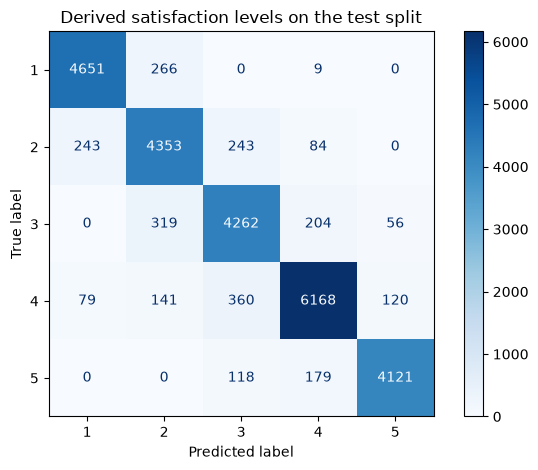

In [4]:
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=[1, 2, 3, 4, 5],
                                        cmap="Blues")
plt.title("Derived satisfaction levels on the test split")
plt.tight_layout()
plt.show()